# Avance 2: Análisis Exploratorio de Datos (EDA)

Este notebook contiene el **Análisis Exploratorio de Datos (EDA)** para el proyecto sobre el impacto de las áreas verdes en la tasa de hurtos en la Región Metropolitana (2023).

Aborda los aspectos exigidos en la pauta del Avance 2:
- **Sección 3.2:** Análisis univariado de variables clave ($Y$, $X$, contexto socioeconómico y tipología).
- **Sección 3.3:** Relaciones entre variables (análisis bivariado $X$ vs $Y$, matriz de correlación y patrones multivariados).


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join('..', 'data', 'processed', 'comunas_rm_consolidado_2023.csv'))

FIG_DIR = os.path.join('..', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Colores fijos por variable (se mantendrán en todo el proyecto)
COLOR_Y = 'C3'        # rojo: hurtos
COLOR_X = 'C2'        # verde: áreas verdes
COLOR_CTX = 'C7'      # gris: contexto socioeconómico

print(f'Comunas cargadas: {len(df)}')

Comunas cargadas: 52


---
## 1. Variable objetivo $Y$: Tasa de hurtos por cada 100.000 habitantes
Usamos un **histograma** para ver la forma de la distribución y un **boxplot** para identificar los valores extremos.

count      52.0
mean      484.1
std       439.4
min       152.1
25%       256.2
50%       352.8
75%       524.6
max      2795.1
Name: tasa_hurtos_100k, dtype: float64

Asimetría (skew): 3.44


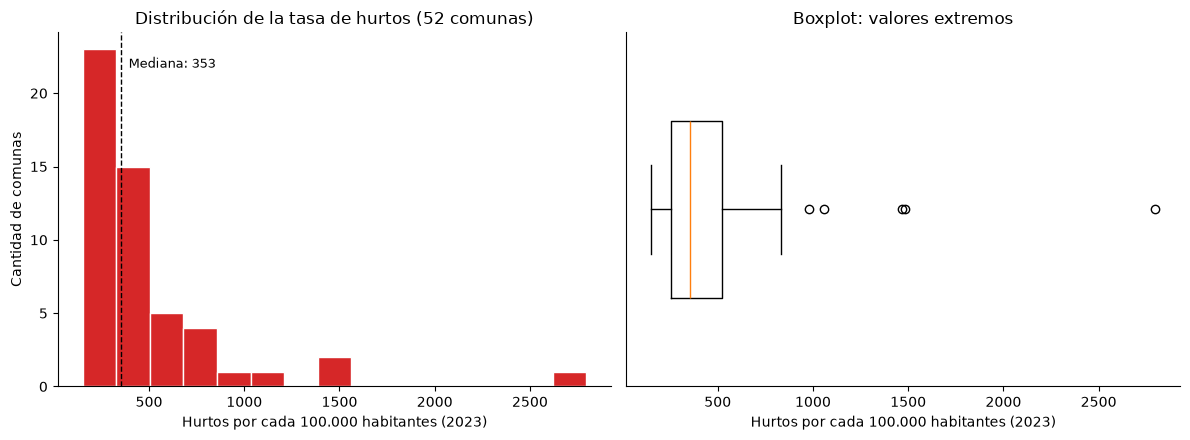

In [2]:
y = df['tasa_hurtos_100k']
print(y.describe().round(1))
print(f'\nAsimetría (skew): {y.skew():.2f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.hist(y, bins=15, color=COLOR_Y, edgecolor='white')
ax1.axvline(y.median(), color='black', linestyle='--', linewidth=1)
ax1.text(y.median() + 40, ax1.get_ylim()[1] * 0.9, f'Mediana: {y.median():.0f}', fontsize=9)
ax1.set_title('Distribución de la tasa de hurtos (52 comunas)')
ax1.set_xlabel('Hurtos por cada 100.000 habitantes (2023)')
ax1.set_ylabel('Cantidad de comunas')

ax2.boxplot(y, orientation='horizontal', widths=0.5)
ax2.set_title('Boxplot: valores extremos')
ax2.set_xlabel('Hurtos por cada 100.000 habitantes (2023)')
ax2.set_yticks([])

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'distribucion_tasa_hurtos.png'), dpi=150, bbox_inches='tight')
plt.show()

In [3]:
# Identificación de outliers con la regla del rango intercuartílico (IQR)
q1, q3 = y.quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)
print(f'Límite superior (Q3 + 1,5·IQR): {limite_superior:.1f}')

outliers_y = df[y > limite_superior][['comuna', 'tasa_hurtos_100k', 'total_hurtos_2023', 'poblacion']]
outliers_y.sort_values('tasa_hurtos_100k', ascending=False)

Límite superior (Q3 + 1,5·IQR): 927.3


,comuna,tasa_hurtos_100k,total_hurtos_2023,poblacion
22,Providencia,2795.063170,4595.0,164397.0
5,Estación Central,1481.315128,3298.0,222640.0
0,Santiago,1468.487264,8038.0,547366.0
12,La Reina,1059.585257,1049.0,99001.0
1,Cerrillos,981.185627,885.0,90197.0


In [4]:
# Concentración de los casos en números absolutos
top5 = df.nlargest(5, 'total_hurtos_2023')
porcentaje = top5['total_hurtos_2023'].sum() / df['total_hurtos_2023'].sum() * 100
print(f'Las 5 comunas con más hurtos concentran el {porcentaje:.1f}% de los casos de la RM:')
print(top5[['comuna', 'total_hurtos_2023']].to_string(index=False))

Las 5 comunas con más hurtos concentran el 45.3% de los casos de la RM:
          comuna  total_hurtos_2023
        Santiago             8038.0
     Providencia             4595.0
Estación Central             3298.0
      La Florida             3259.0
      Las Condes             2866.0


### 🔍 Interpretación de $Y$
- **Distribución muy asimétrica a la derecha** (skew = 3,44): la media (484) es bastante mayor que la mediana (353). La mayoría de las comunas tiene tasas moderadas (el 50% central está entre 256 y 525 hurtos por 100.000 hab), pero unas pocas tienen valores muy altos.
- **5 comunas atípicas:** Providencia (2.795), Estación Central (1.481), Santiago (1.468), La Reina (1.060) y Cerrillos (981). Providencia duplica a la segunda comuna.
- **Alta concentración:** las 5 comunas con más casos absolutos (Santiago, Providencia, Estación Central, La Florida y Las Condes) acumulan el **45,3%** de los hurtos de la RM.

**Limitación importante:** la tasa se calcula con la población *residente*. En comunas céntricas y comerciales (Santiago, Providencia, Estación Central) circulan diariamente muchas más personas que las que viven ahí (población flotante), por lo que la tasa tiende a **sobreestimar** el riesgo por residente en esas comunas.

**Decisión:** los outliers **no se eliminan**, porque son comunas reales y son parte del fenómeno que queremos estudiar. En el análisis de relaciones (análisis de relaciones) se considerará su efecto (por ejemplo, revisando los resultados con y sin ellas).

---
## 2. Variable explicativa $X$: Metros cuadrados de áreas verdes por habitante
Se analizan las **44 comunas con catastro MINVU** (las 8 comunas sin catastro quedan fuera, ver preparación de datos).  
En el histograma se marca como referencia el valor de **9 m²/hab**, ampliamente citado como estándar recomendado (atribuido a la OMS).

count    44.00
mean      5.10
std       4.36
min       0.18
25%       2.42
50%       3.51
75%       5.17
max      16.27
Name: m2_areas_verdes_per_capita, dtype: float64

Asimetría (skew): 1.48
Comunas con 9 m²/hab o más: 7 de 44


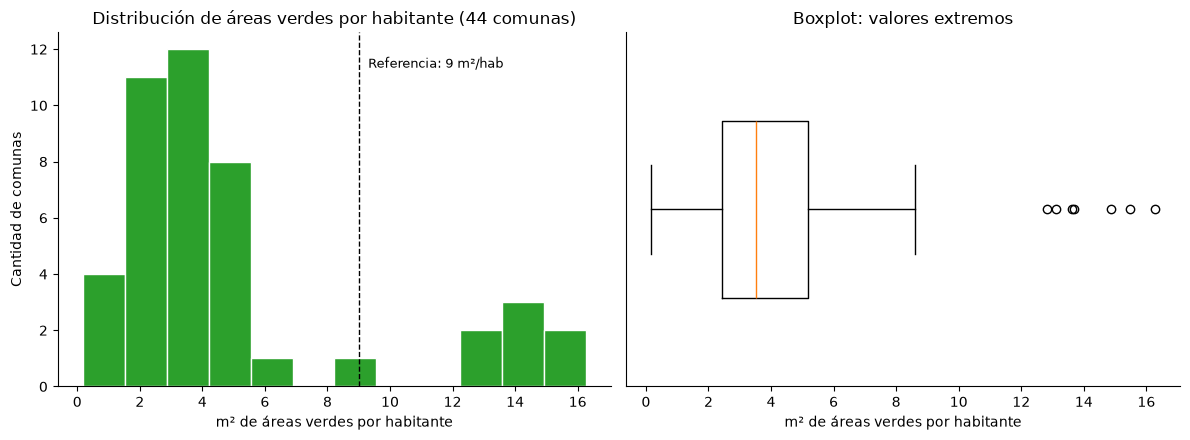

In [5]:
x = df['m2_areas_verdes_per_capita'].dropna()
print(x.describe().round(2))
print(f'\nAsimetría (skew): {x.skew():.2f}')
print(f'Comunas con 9 m²/hab o más: {(x >= 9).sum()} de {len(x)}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.hist(x, bins=12, color=COLOR_X, edgecolor='white')
ax1.axvline(9, color='black', linestyle='--', linewidth=1)
ax1.text(9.3, ax1.get_ylim()[1] * 0.9, 'Referencia: 9 m²/hab', fontsize=9)
ax1.set_title('Distribución de áreas verdes por habitante (44 comunas)')
ax1.set_xlabel('m² de áreas verdes por habitante')
ax1.set_ylabel('Cantidad de comunas')

ax2.boxplot(x, orientation='horizontal', widths=0.5)
ax2.set_title('Boxplot: valores extremos')
ax2.set_xlabel('m² de áreas verdes por habitante')
ax2.set_yticks([])

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'distribucion_m2_per_capita.png'), dpi=150, bbox_inches='tight')
plt.show()

In [6]:
q1, q3 = x.quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)
print(f'Límite superior (Q3 + 1,5·IQR): {limite_superior:.2f} m²/hab\n')

print('Comunas atípicas (más áreas verdes por habitante):')
print(df[df['m2_areas_verdes_per_capita'] > limite_superior]
      .sort_values('m2_areas_verdes_per_capita', ascending=False)[['comuna', 'm2_areas_verdes_per_capita']]
      .to_string(index=False))

print('\nComunas con menos áreas verdes por habitante:')
print(df.nsmallest(5, 'm2_areas_verdes_per_capita')[['comuna', 'm2_areas_verdes_per_capita']].to_string(index=False))

Límite superior (Q3 + 1,5·IQR): 9.29 m²/hab

Comunas atípicas (más áreas verdes por habitante):
      comuna  m2_areas_verdes_per_capita
    Vitacura                   16.270196
  Huechuraba                   15.474952
    Recoleta                   14.861582
   Cerrillos                   13.692753
    La Reina                   13.629998
 Providencia                   13.104405
Lo Barnechea                   12.837707

Comunas con menos áreas verdes por habitante:
           comuna  m2_areas_verdes_per_capita
           Pirque                    0.176862
San José De Maipo                    0.190199
    Independencia                    1.017196
       San Miguel                    1.440803
      La Cisterna                    1.581885


### 🔍 Interpretación de $X$
- **Distribución asimétrica a la derecha** (skew = 1,48): la mediana es **3,5 m²/hab** y la media 5,1 m²/hab. La mitad de las comunas con catastro tiene menos de 3,5 m² por habitante.
- **Solo 7 de 44 comunas alcanzan los 9 m²/hab** de referencia: Vitacura (16,3), Huechuraba (15,5), Recoleta (14,9), Cerrillos (13,7), La Reina (13,6), Providencia (13,1) y Lo Barnechea (12,8). Son además los valores atípicos del boxplot.
- La mayoría de estas comunas son del sector oriente y de altos ingresos, pero **Recoleta y Cerrillos rompen ese patrón**. Conviene revisar qué espacios explican sus valores (por ejemplo, la presencia de grandes parques).
- En el extremo inferior hay dos casos distintos:
  - **Pirque (0,18) y San José de Maipo (0,19):** comunas semi-rurales donde el catastro urbano cubre una parte pequeña del territorio. Su valor bajo refleja la **cobertura del catastro**, no necesariamente falta de naturaleza.
  - **Independencia (1,0), San Miguel (1,4) y La Cisterna (1,6):** comunas urbanas densas con un **déficit real** de áreas verdes.

---
## 3. Variable de contexto: Porcentaje de pobreza por ingresos
Esta variable no es parte directa de la pregunta, pero la incorporamos porque puede influir tanto en las áreas verdes como en los hurtos (variable de contexto).

count    52.0
mean     14.5
std       5.4
min       0.8
25%      12.0
50%      15.2
75%      18.4
max      23.3
Name: pct_pobreza, dtype: float64

Asimetría (skew): -0.80


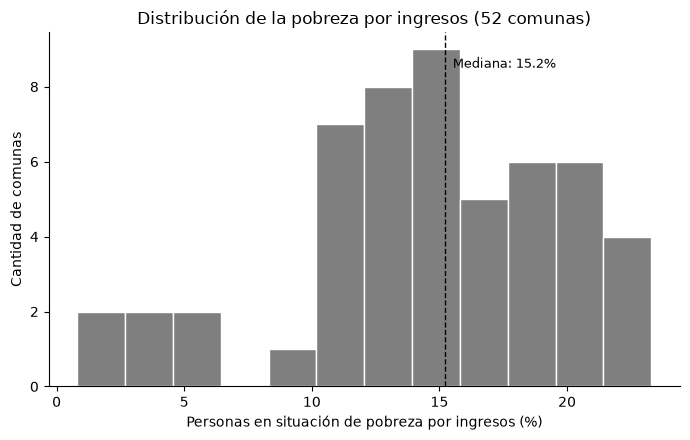

Comunas con mayor pobreza:
    comuna  pct_pobreza
La Pintana     0.233008
     Alhué     0.232055
 San Pedro     0.222198

Comunas con menor pobreza:
      comuna  pct_pobreza
    Vitacura     0.008107
 Providencia     0.011865
Lo Barnechea     0.027503


In [7]:
p = df['pct_pobreza'] * 100   # en porcentaje
print(p.describe().round(1))
print(f'\nAsimetría (skew): {p.skew():.2f}')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(p, bins=12, color=COLOR_CTX, edgecolor='white')
ax.axvline(p.median(), color='black', linestyle='--', linewidth=1)
ax.text(p.median() + 0.3, ax.get_ylim()[1] * 0.9, f'Mediana: {p.median():.1f}%', fontsize=9)
ax.set_title('Distribución de la pobreza por ingresos (52 comunas)')
ax.set_xlabel('Personas en situación de pobreza por ingresos (%)')
ax.set_ylabel('Cantidad de comunas')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'distribucion_pobreza.png'), dpi=150, bbox_inches='tight')
plt.show()

print('Comunas con mayor pobreza:')
print(df.nlargest(3, 'pct_pobreza')[['comuna', 'pct_pobreza']].to_string(index=False))
print('\nComunas con menor pobreza:')
print(df.nsmallest(3, 'pct_pobreza')[['comuna', 'pct_pobreza']].to_string(index=False))

### 🔍 Interpretación de la pobreza
- **Asimetría hacia la izquierda** (skew = -0,80): la mayoría de las comunas está entre 12% y 18% de pobreza (mediana 15,2%), y existe un **pequeño grupo con pobreza muy baja**: Vitacura (0,8%), Providencia (1,2%) y Lo Barnechea (2,8%).
- Las comunas con mayor pobreza son La Pintana (23,3%), Alhué (23,2%) y San Pedro (22,2%).
- **Observación clave para el análisis bivariado:** las comunas con menos pobreza (Vitacura, Providencia, Lo Barnechea) son **las mismas** que aparecen con más áreas verdes por habitante. Es decir, la pobreza podría estar relacionada con $X$, y por lo tanto debe considerarse al analizar la relación entre áreas verdes y hurtos.

---
## 4. Composición de las áreas verdes: plazas vs. parques
Variable categórica: frecuencia de cada tipo de espacio público en la RM. Usamos un **gráfico de barras**, adecuado para comparar categorías.

         cantidad  porcentaje
Plazas       7550        92.5
Parques       610         7.5


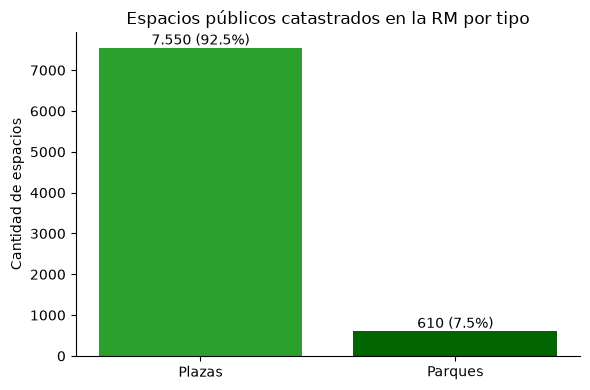

In [8]:
conteo = pd.Series({
    'Plazas': int(df['cantidad_plazas'].sum()),
    'Parques': int(df['cantidad_parques'].sum()),
})
porcentaje = conteo / conteo.sum() * 100
print(pd.DataFrame({'cantidad': conteo, 'porcentaje': porcentaje.round(1)}))

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(conteo.index, conteo.values, color=[COLOR_X, 'darkgreen'])
for barra, pct in zip(barras, porcentaje):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 80,
            f'{int(barra.get_height()):,} ({pct:.1f}%)'.replace(',', '.'), ha='center', fontsize=10)
ax.set_title('Espacios públicos catastrados en la RM por tipo')
ax.set_ylabel('Cantidad de espacios')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'plazas_vs_parques.png'), dpi=150, bbox_inches='tight')
plt.show()

### 🔍 Interpretación
- El **92,5%** de los 8.160 espacios catastrados son **plazas** y solo el **7,5%** son parques.
- Por esto, contar "cantidad de espacios" mide principalmente plazas pequeñas. Para representar la disponibilidad de áreas verdes es más adecuado usar la **superficie (m² por habitante)**, que es la variable $X$ elegida.

---
## 5. Resumen de hallazgos del análisis univariado
1. **$Y$ (tasa de hurtos)** está muy concentrada: la mayoría de las comunas tiene tasas moderadas, pero unas pocas comunas céntricas/comerciales (Providencia, Estación Central, Santiago) presentan valores extremos, probablemente influidos por la población flotante.
2. **$X$ (m² por habitante)** también es asimétrica: la mitad de las comunas tiene menos de 3,5 m²/hab y solo 7 de 44 superan los 9 m²/hab.
3. **La pobreza** muestra un grupo pequeño de comunas con pobreza muy baja, que coincide con las comunas con más áreas verdes.
4. **Las plazas dominan** el catastro, por lo que la superficie es mejor medida de $X$ que el conteo de espacios.

### Decisiones para el análisis de relaciones entre variables (Sección 3.3)
- Mantener los outliers, pero revisar si los resultados cambian al excluirlos.
- Como ambas variables son asimétricas, observar la relación con cuidado (por ejemplo, usar la mediana en las comparaciones).
- Incorporar la pobreza al analizar la relación $X$ vs $Y$, ya que parece estar relacionada con ambas.

---
## 6. Relaciones entre variables (Sección 3.3 de la pauta)

En esta sección avanzamos desde la descripción univariada hacia el **estudio de relaciones bivariadas y multivariadas**, respondiendo a la pregunta central:  
*¿Qué variables parecen estar relacionadas con la tasa de hurtos ($Y$), y qué rol juegan las áreas verdes ($X$) y el contexto socioeconómico?*


=== CORRELACIÓN ENTRE ÁREAS VERDES (X) Y TASA DE HURTOS (Y) ===
Todas las comunas (N = 44):
  - Correlación de Pearson (lineal):    r = 0.371
  - Correlación de Spearman (rangos):  rho = 0.228

Excluyendo outliers comerciales (Providencia y Santiago, N = 42):
  - Correlación de Pearson (lineal):    r = 0.324
  - Correlación de Spearman (rangos):  rho = 0.207


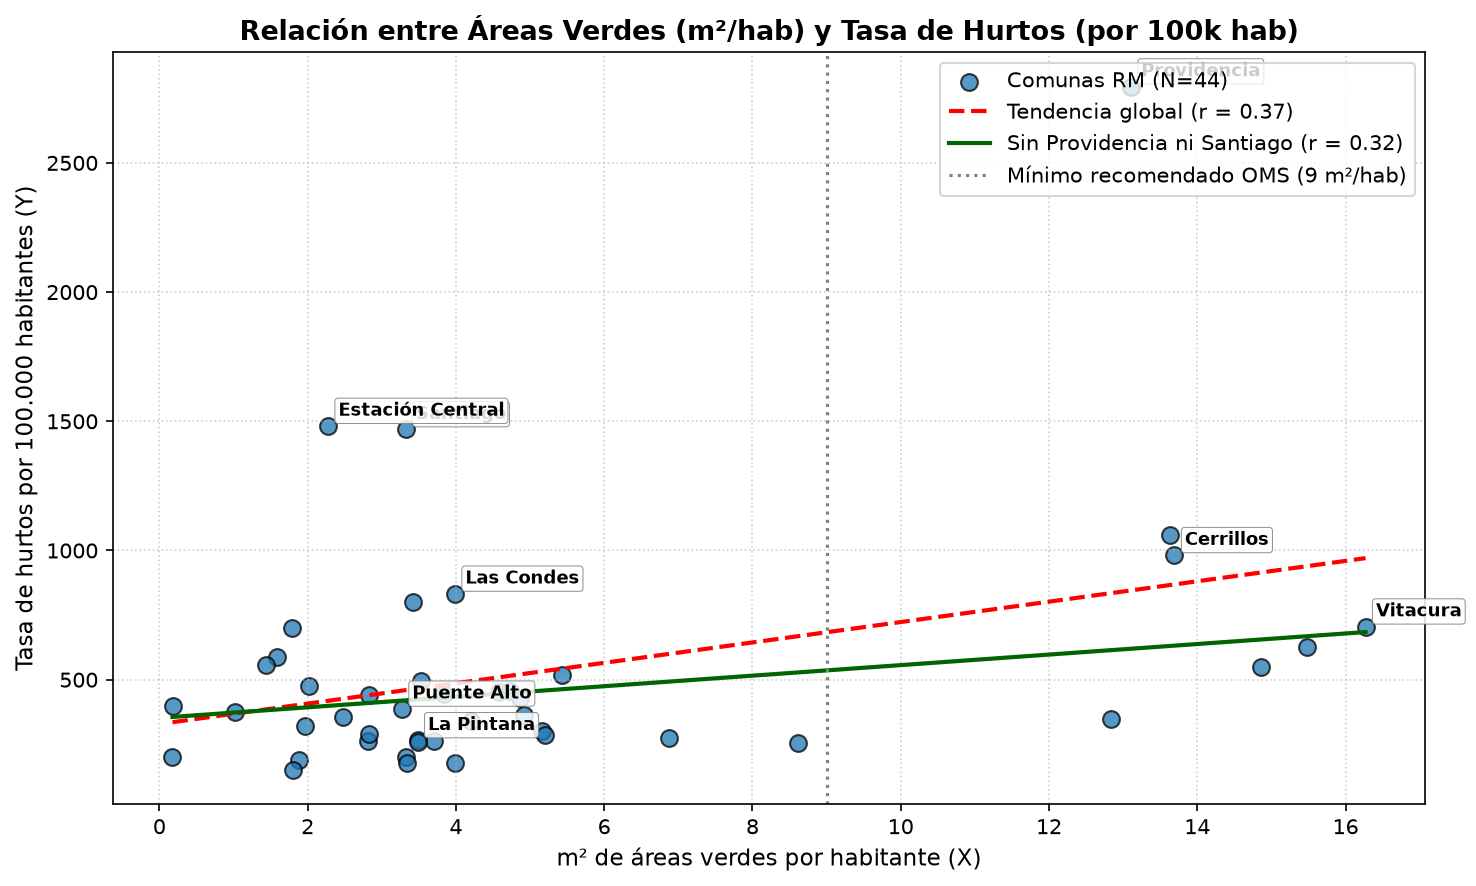

In [9]:
# 6.1 Relación bivariada: m² de áreas verdes per cápita (X) vs Tasa de hurtos por 100k hab (Y)

import numpy as np



# Filtramos las 44 comunas con catastro MINVU

df_cat = df[df['tiene_catastro_minvu']].copy()



x = df_cat['m2_areas_verdes_per_capita']

y = df_cat['tasa_hurtos_100k']



# Correlaciones globales

r_pearson = df_cat[['m2_areas_verdes_per_capita', 'tasa_hurtos_100k']].corr(method='pearson').iloc[0, 1]

r_spearman = df_cat[['m2_areas_verdes_per_capita', 'tasa_hurtos_100k']].corr(method='spearman').iloc[0, 1]



# Correlaciones excluyendo outliers comerciales (Providencia y Santiago)

sin_out = df_cat[~df_cat['comuna'].isin(['Providencia', 'Santiago'])]

r_pearson_sin = sin_out[['m2_areas_verdes_per_capita', 'tasa_hurtos_100k']].corr(method='pearson').iloc[0, 1]

r_spearman_sin = sin_out[['m2_areas_verdes_per_capita', 'tasa_hurtos_100k']].corr(method='spearman').iloc[0, 1]



print("=== CORRELACIÓN ENTRE ÁREAS VERDES (X) Y TASA DE HURTOS (Y) ===")

print(f"Todas las comunas (N = {len(df_cat)}):")

print(f"  - Correlación de Pearson (lineal):    r = {r_pearson:.3f}")

print(f"  - Correlación de Spearman (rangos):  rho = {r_spearman:.3f}")

print(f"\nExcluyendo outliers comerciales (Providencia y Santiago, N = {len(sin_out)}):")

print(f"  - Correlación de Pearson (lineal):    r = {r_pearson_sin:.3f}")

print(f"  - Correlación de Spearman (rangos):  rho = {r_spearman_sin:.3f}")



# Gráfico de dispersión

fig, ax = plt.subplots(figsize=(10, 6))



ax.scatter(x, y, color='tab:blue', alpha=0.75, edgecolors='black', s=65, label='Comunas RM (N=44)')



# Línea de tendencia global (OLS)

m_tot, b_tot = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)

ax.plot(x_line, m_tot * x_line + b_tot, color='red', linestyle='--', linewidth=2,

        label=f'Tendencia global (r = {r_pearson:.2f})')



# Línea de tendencia sin outliers

m_sin, b_sin = np.polyfit(sin_out['m2_areas_verdes_per_capita'], sin_out['tasa_hurtos_100k'], 1)

ax.plot(x_line, m_sin * x_line + b_sin, color='darkgreen', linestyle='-', linewidth=2,

        label=f'Sin Providencia ni Santiago (r = {r_pearson_sin:.2f})')



# Referencia estándar OMS (9 m²/hab)

ax.axvline(9.0, color='gray', linestyle=':', linewidth=1.5, label='Mínimo recomendado OMS (9 m²/hab)')



# Anotar comunas clave

destacadas = ['Providencia', 'Santiago', 'Estación Central', 'Vitacura', 'Las Condes', 'Cerrillos', 'La Pintana', 'Puente Alto']

for _, row in df_cat[df_cat['comuna'].isin(destacadas)].iterrows():

    ax.annotate(row['comuna'], (row['m2_areas_verdes_per_capita'], row['tasa_hurtos_100k']),

                textcoords='offset points', xytext=(5, 5), fontsize=8.5, fontweight='bold',

                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5))



ax.set_title('Relación entre Áreas Verdes (m²/hab) y Tasa de Hurtos (por 100k hab)', fontsize=13, fontweight='bold')

ax.set_xlabel('m² de áreas verdes por habitante (X)', fontsize=11)

ax.set_ylabel('Tasa de hurtos por 100.000 habitantes (Y)', fontsize=11)

ax.grid(True, linestyle=':', alpha=0.6)

ax.legend(frameon=True, loc='upper right')



plt.tight_layout()

plt.savefig(os.path.join(FIG_DIR, 'relacion_areas_verdes_vs_hurtos.png'), dpi=150, bbox_inches='tight')

plt.show()


### 🔍 Interpretación de la relación bivariada ($X$ vs $Y$)

* **Visualización:** Gráfico de dispersión con líneas de tendencia lineal (con y sin outliers) y el umbral de referencia de la OMS.
* **Observación:**
  1. La correlación entre m² de áreas verdes por habitante y la tasa de hurtos es **positiva débil a moderada** ($r = 0,371$; Spearman $\rho = 0,228$).
  2. Si retiramos los dos mayores outliers comerciales (Providencia y Santiago), la correlación lineal se mantiene prácticamente constante ($r = 0,324$).
  3. No se observa una reducción en la tasa de hurtos a medida que aumenta la disponibilidad de áreas verdes.
* **Interpretación:**
  * Este resultado parece contraintuitivo frente a la hipótesis ingenua de que *"más áreas verdes implican barrios más tranquilos o seguros"*.
  * Sin embargo, el **hurto es un delito patrimonial no violento de oportunidad** (carterismo, sustracción en centros comerciales, tiendas y transporte público). Las comunas con alta dotación de áreas verdes per cápita (como Providencia, Vitacura o Las Condes) son comunas de altos ingresos y alta atracción comercial, donde confluye una enorme población flotante y se concentran bienes de alto valor.
* **Conexión con la pregunta del proyecto:**
  * Las áreas verdes no determinan directamente una reducción del hurto. Para entender qué está ocurriendo realmente, es indispensable incorporar la dimensión socioeconómica y la concentración comercial.


=== MATRIZ DE CORRELACIÓN DE PEARSON (LINEAL) ===
                            tasa_hurtos_100k  ...  pct_pobreza
tasa_hurtos_100k                       1.000  ...       -0.517
m2_areas_verdes_per_capita             0.371  ...       -0.395
espacios_por_10k_hab                  -0.191  ...        0.108
pct_pobreza                           -0.517  ...        1.000

[4 rows x 4 columns]

=== MATRIZ DE CORRELACIÓN DE SPEARMAN (MONÓTONA / RANGOS) ===
                            tasa_hurtos_100k  ...  pct_pobreza
tasa_hurtos_100k                       1.000  ...       -0.516
m2_areas_verdes_per_capita             0.228  ...       -0.039
espacios_por_10k_hab                  -0.116  ...        0.187
pct_pobreza                           -0.516  ...        1.000

[4 rows x 4 columns]


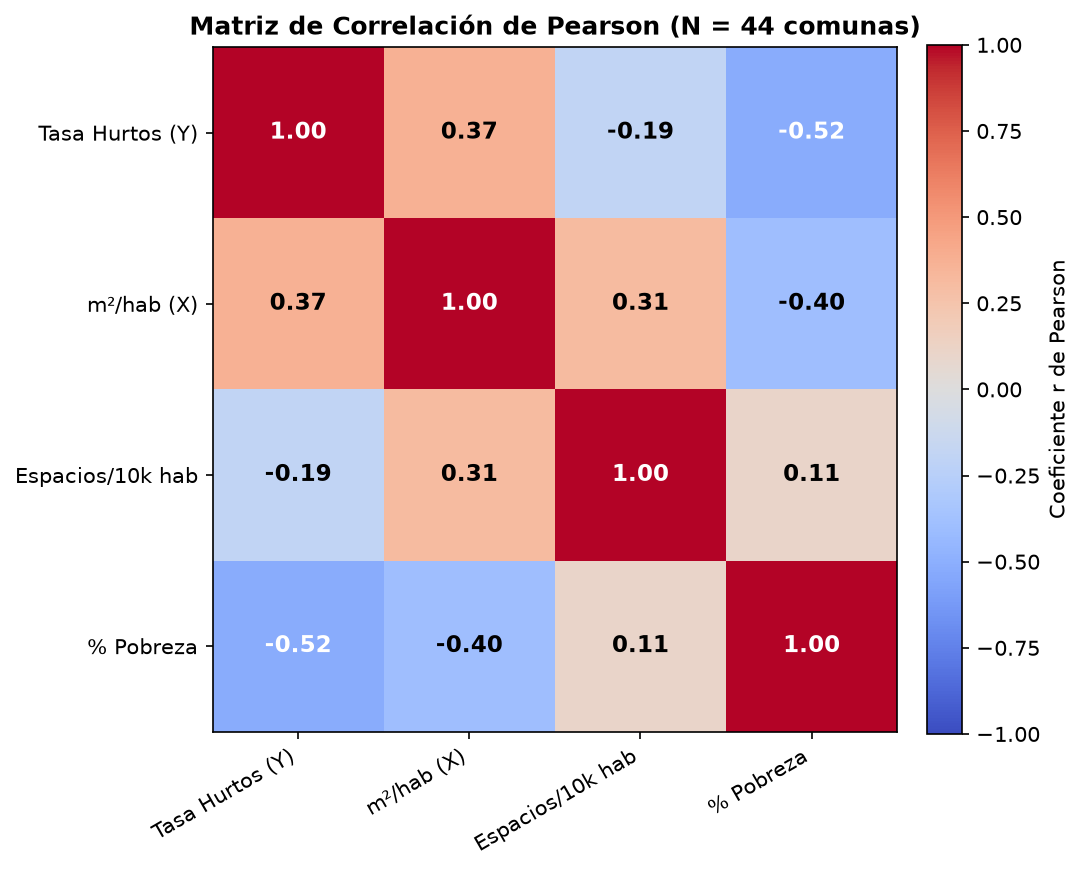

In [10]:
# 6.2 Matriz de correlación entre variables numéricas

vars_corr = ['tasa_hurtos_100k', 'm2_areas_verdes_per_capita', 'espacios_por_10k_hab', 'pct_pobreza']

nombres_corr = ['Tasa Hurtos (Y)', 'm²/hab (X)', 'Espacios/10k hab', '% Pobreza']



corr_p = df_cat[vars_corr].corr(method='pearson')

corr_s = df_cat[vars_corr].corr(method='spearman')



print("=== MATRIZ DE CORRELACIÓN DE PEARSON (LINEAL) ===")

print(corr_p.round(3))



print("\n=== MATRIZ DE CORRELACIÓN DE SPEARMAN (MONÓTONA / RANGOS) ===")

print(corr_s.round(3))



fig, ax = plt.subplots(figsize=(7, 6))

cax = ax.imshow(corr_p.values, cmap='coolwarm', vmin=-1, vmax=1)

fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04, label='Coeficiente r de Pearson')



ax.set_xticks(range(len(vars_corr)))

ax.set_yticks(range(len(vars_corr)))

ax.set_xticklabels(nombres_corr, rotation=30, ha='right', fontsize=10)

ax.set_yticklabels(nombres_corr, fontsize=10)



for i in range(len(vars_corr)):

    for j in range(len(vars_corr)):

        val = corr_p.values[i, j]

        color = 'white' if abs(val) > 0.45 else 'black'

        ax.text(j, i, f'{val:.2f}', ha='center', va='center', color=color, fontweight='bold', fontsize=11)



ax.set_title('Matriz de Correlación de Pearson (N = 44 comunas)', fontsize=12, fontweight='bold')

plt.tight_layout()

plt.savefig(os.path.join(FIG_DIR, 'matriz_correlacion.png'), dpi=150, bbox_inches='tight')

plt.show()


### 🔍 Interpretación de la matriz de correlación

* **Visualización:** Matriz de calor (heatmap) con coeficientes de Pearson y tabla complementaria de Spearman.
* **Observación:**
  1. **Hurtos vs Pobreza:** La correlación entre `% de pobreza` y la `tasa de hurtos` es **negativa y moderada-fuerte** ($r = -0,517$; Spearman $\rho = -0,516$). Es la correlación más intensa de todas las variables analizadas.
  2. **Áreas verdes vs Pobreza:** Existe correlación negativa entre `% de pobreza` y `m² por habitante` ($r = -0,395$), confirmando la desigualdad en acceso a espacios públicos.
  3. **Cantidad de espacios vs Hurtos:** La densidad de plazas y parques por habitante (`espacios_por_10k_hab`) no presenta correlación apreciable con hurtos ($r = -0,191$; $\rho = -0,116$).
* **Interpretación:**
  * **La pobreza actúa como variable de confusión (*confounding variable*):** En comunas de menor nivel socioeconómico (mayor pobreza), la tasa de denuncias de hurto por habitante es significativamente menor. Esto ocurre porque la actividad comercial y bancaria se concentra en sectores de mayor poder adquisitivo y polos de servicios, además de una probable mayor cifra negra (sub-denuncia) de hurtos menores en zonas periféricas.
  * Por tanto, la relación positiva aparente entre áreas verdes y hurtos está fuertemente mediada por el hecho de que las comunas con más áreas verdes son comunas de altos ingresos y con gran infraestructura comercial.


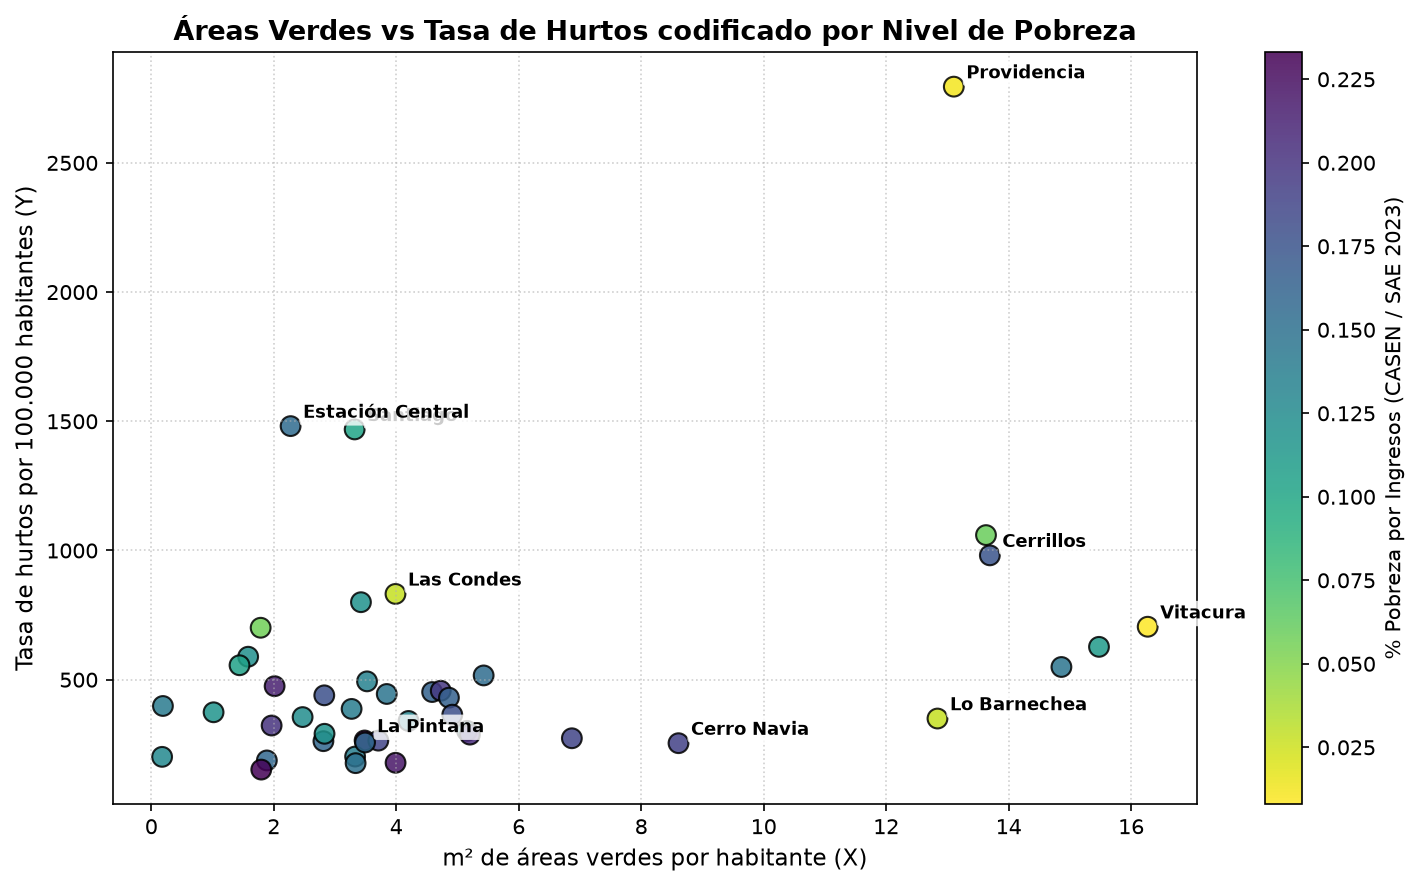

In [11]:
# 6.3 Relación multivariada: Áreas Verdes vs Hurtos, condicionada por el nivel de pobreza

fig, ax = plt.subplots(figsize=(10, 6))



sc = ax.scatter(

    df_cat['m2_areas_verdes_per_capita'], 

    df_cat['tasa_hurtos_100k'],

    c=df_cat['pct_pobreza'], 

    cmap='viridis_r', 

    s=90, 

    edgecolors='black', 

    alpha=0.85

)



cbar = fig.colorbar(sc, ax=ax)

cbar.set_label('% Pobreza por Ingresos (CASEN / SAE 2023)', fontsize=10)



# Anotaciones de comunas representativas de cada grupo

comunas_rotular = {

    'Providencia': 'Grupo 1: Comercial extremo',

    'Santiago': 'Grupo 1: Centro histórico/comercial',

    'Estación Central': 'Grupo 1: Eje comercial/terminales',

    'Vitacura': 'Grupo 2: Alto ingreso / Máx áreas verdes',

    'Lo Barnechea': 'Grupo 2: Alto ingreso',

    'Las Condes': 'Grupo 2: Alto ingreso / Comercial',

    'La Pintana': 'Grupo 3: Vulnerable / Bajo m²',

    'Cerro Navia': 'Grupo 3: Vulnerable / Bajo m²',

    'Cerrillos': 'Transición'

}



for com, desc in comunas_rotular.items():

    sub = df_cat[df_cat['comuna'] == com]

    if len(sub) > 0:

        row = sub.iloc[0]

        ax.annotate(com, (row['m2_areas_verdes_per_capita'], row['tasa_hurtos_100k']),

                    textcoords='offset points', xytext=(6, 4), fontsize=8.5, fontweight='bold',

                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none'))



ax.set_title('Áreas Verdes vs Tasa de Hurtos codificado por Nivel de Pobreza', fontsize=13, fontweight='bold')

ax.set_xlabel('m² de áreas verdes por habitante (X)', fontsize=11)

ax.set_ylabel('Tasa de hurtos por 100.000 habitantes (Y)', fontsize=11)

ax.grid(True, linestyle=':', alpha=0.6)



plt.tight_layout()

plt.savefig(os.path.join(FIG_DIR, 'relacion_hurtos_areas_verdes_pobreza.png'), dpi=150, bbox_inches='tight')

plt.show()


### 🔍 Interpretación y grupos identificados

* **Visualización:** Gráfico de dispersión multivariado donde el color representa el porcentaje de pobreza comunal (colores más amarillos = mayor pobreza; colores púrpuras = menor pobreza).
* **Identificación de 3 grupos clave:**
  1. **Grupo 1: Polos de centralidad comercial y transporte (Outliers en Y):**  
     *Comunas:* Providencia, Santiago, Estación Central.  
     *Patrón:* Tasa de hurtos extremadamente alta ($> 1.400$ por 100k hab), independientemente de sus m² de áreas verdes. Se caracterizan por malls, centros cívicos y estaciones terminales donde la población flotante supera con creces a la población residente.
  2. **Grupo 2: Sector Oriente / Alto Nivel Socioeconómico:**  
     *Comunas:* Vitacura, Las Condes, Lo Barnechea, La Reina.  
     *Patrón:* Pobreza prácticamente nula ($< 4\%$), alta dotación de áreas verdes ($> 6\text{ m}^2/\text{hab}$, superando el estándar OMS), y tasas de hurtos moderadas-altas ($400 - 650$ por 100k hab).
  3. **Grupo 3: Comunas Periféricas y Vulnerables:**  
     *Comunas:* La Pintana, Cerro Navia, Lo Espejo, San Ramón, Puente Alto.  
     *Patrón:* Pobreza superior al $18\%$, severo déficit de áreas verdes ($< 2,5\text{ m}^2/\text{hab}$), y tasas de hurtos moderadas o bajas ($150 - 350$ por 100k hab).


---
## 7. Conclusiones de las relaciones frente a la pregunta del proyecto

1. **¿Existe relación entre áreas verdes y hurtos?**  
   Existe una correlación estadística positiva débil a moderada ($r \approx 0,37$), pero **no es causal directa**. Se descarta la hipótesis ingenua de que mayor superficie de áreas verdes reduzca de por sí los hurtos.
2. **Naturaleza del delito de hurto:**  
   El hurto es una sustracción sin violencia física que prolifera en lugares de aglomeración y comercio. Las comunas con mayores áreas verdes per cápita coinciden con los sectores de mayor renta y actividad comercial de la ciudad.
3. **Pobreza como variable explicativa clave:**  
   La correlación negativa entre pobreza y hurtos ($r = -0,52$) refleja que las denuncias de hurto se concentran donde hay circulación de bienes y flujo comercial, y no en las comunas vulnerables.
4. **Implicancia para la aplicación interactiva:**  
   La aplicación en Streamlit debe permitir explorar cómo cambian estos patrones al filtrar los outliers comerciales (Providencia y Santiago) y al segmentar por nivel de pobreza comunal.

### 💡 Nota analítica: ¿Por qué el hurto no disminuye con más áreas verdes?
> **Contraste con delitos violentos (Homicidios y Armas):**  
> En un análisis inicial podría asumirse que mayor inversión comunal y áreas verdes reducirían la delincuencia. Sin embargo, un contraste con las demás categorías delictivas del CEAD demuestra que este comportamiento depende estrictamente del tipo de delito:
> - **En delitos violentos extremos (Homicidios y Delitos con Armas):** La relación con el equipamiento e ingreso comunal sí es fuertemente inversa. La tasa de homicidios se correlaciona de forma marcadamente positiva con la pobreza ($r = +0,51$) y disminuye en comunas con mayor inversión urbana y áreas verdes (en Vitacura la tasa fue de $1,0$ por 100k hab, mientras que en Lo Espejo y La Pintana superó los $11 - 14$).
> - **En el delito de Hurto:** Al ser un delito patrimonial no violento de oportunidad, prolifera en zonas comerciales, estaciones de transporte y sectores de altos ingresos donde concurre población flotante y circulan bienes de valor. Por ello, se asocia positivamente a comunas con alta dotación de espacio público y menor pobreza.
